In [ ]:
!wget -q -O geometric_properties.csv "https://zenodo.org/records/16802743/files/geometric_properties.csv?download=1"
!wget -q -O post_comb_vsa-CO2.csv "https://zenodo.org/records/16802743/files/post_comb_vsa-CO2.csv?download=1"

import pandas as pd
geo = pd.read_csv("geometric_properties.csv")
co2 = pd.read_csv("post_comb_vsa-CO2.csv")
print(geo.shape, co2.shape)
print(geo.columns.tolist())
print(co2.columns.tolist())
print(co2.head())

(521316, 29) (559220, 19)
['Unnamed: 0', 'filename', 'UC_volume', 'Density', 'ASA', 'vASA', 'gASA', 'NASA', 'gNASA', 'vNASA', 'AVA', 'AVAf', 'AVAg', 'NAVA', 'NAVAf', 'NAVAg', 'POAVA', 'POAVAf', 'POAVAg', 'NPOAVA', 'NPOAVAf', 'NPOAVAg', 'Di', 'Df', 'Dif', 'ARC-MOF', 'DB_num', 'order_geo', 'bool_geo']
['filename', 'T/K', 'p/bar', 'molc/uc', 'mmol/g', 'stdev', 'v/v', 'stdev.1', 'wt%', 'stdev.2', 'hoa/kcal/mol', 'stdev.3', 'C_v', 'stdev.4', 'S(g1)', 'S(g1)_err', 'f/bar', 'p(g0)', 'p(g1)']
                              filename    T/K  p/bar   molc/uc    mmol/g  \
0  DB0-m3_o12_o22_f0_pcu.sym.90_repeat  298.0  0.015  0.040224  0.051907   
1  DB0-m3_o12_o22_f0_pcu.sym.90_repeat  298.0  0.150  0.327377  0.422470   
2    DB0-m2_o2_o7_f0_nbo.sym.27_repeat  298.0  0.015  0.178214  0.034397   
3    DB0-m2_o2_o7_f0_nbo.sym.27_repeat  298.0  0.150  1.279906  0.247034   
4    DB0-m2_o2_o8_f0_pcu.sym.17_repeat  298.0  0.015  0.071228  0.067449   

      stdev       v/v   stdev.1       wt%   stdev.2  

In [ ]:
# 1. CO2 uptake at flue-gas adsorption conditions (0.15 bar CO2)
ads = co2[co2['p/bar'] == 0.15][['filename', 'mmol/g']].rename(columns={'mmol/g': 'CO2_uptake'})

# 2. Geometric descriptors (inputs)
features = ['Di', 'Df', 'Dif', 'Density', 'gASA', 'vASA', 'AVAf', 'POAVAf']
geo_small = geo[['filename'] + features]

# 3. Check the filenames match between the two files
print("CO2 example:", ads['filename'].iloc[0])
print("Geo example:", geo_small['filename'].iloc[0])

# 4. Merge
data = pd.merge(geo_small, ads, on='filename').dropna()
print("Merged MOFs:", len(data))
print(data.describe())

CO2 example: DB0-m3_o12_o22_f0_pcu.sym.90_repeat
Geo example: DB0-m2_o1_o10_f0_pcu.sym.66.cif
Merged MOFs: 0
        Di   Df  Dif  Density  gASA  vASA  AVAf  POAVAf  CO2_uptake
count  0.0  0.0  0.0      0.0   0.0   0.0   0.0     0.0         0.0
mean   NaN  NaN  NaN      NaN   NaN   NaN   NaN     NaN         NaN
std    NaN  NaN  NaN      NaN   NaN   NaN   NaN     NaN         NaN
min    NaN  NaN  NaN      NaN   NaN   NaN   NaN     NaN         NaN
25%    NaN  NaN  NaN      NaN   NaN   NaN   NaN     NaN         NaN
50%    NaN  NaN  NaN      NaN   NaN   NaN   NaN     NaN         NaN
75%    NaN  NaN  NaN      NaN   NaN   NaN   NaN     NaN         NaN
max    NaN  NaN  NaN      NaN   NaN   NaN   NaN     NaN         NaN


In [ ]:
# Make clean, matching names in both tables
ads = ads.copy()
geo_small = geo_small.copy()
ads['name'] = ads['filename'].str.replace('_repeat', '', regex=False)
geo_small['name'] = geo_small['filename'].str.replace('.cif', '', regex=False).str.replace('_repeat', '', regex=False)

# Merge on the cleaned name
data = pd.merge(geo_small.drop(columns='filename'), ads.drop(columns='filename'), on='name').dropna()
print("Merged MOFs:", len(data))
print(data.describe())

Merged MOFs: 279001
                  Di             Df            Dif        Density  \
count  279001.000000  279001.000000  279001.000000  279001.000000   
mean       11.089099       8.365889      11.012634       0.689401   
std         4.794547       3.554706       4.788466       0.303013   
min         1.890660       0.499250       1.890660       0.060833   
25%         7.713100       5.774710       7.638090       0.475904   
50%        10.073270       7.786670      10.002170       0.650917   
75%        13.492530       9.971470      13.400200       0.852942   
max        68.873860      67.429440      68.873860       3.913040   

                gASA           vASA           AVAf         POAVAf  \
count  279001.000000  279001.000000  279001.000000  279001.000000   
mean     3157.403230    1745.959928       0.289080       0.584902   
std      1528.875961     485.152688       0.185757       0.188747   
min         0.000000       0.000000       0.000000       0.000000   
25%      2034

R2 : 0.589
MAE: 0.378 mmol/g


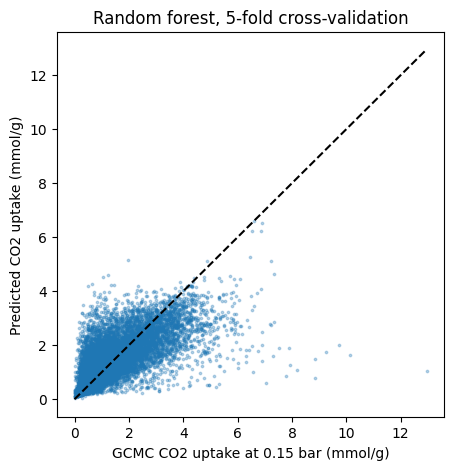

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error
import matplotlib.pyplot as plt

# Random sample for speed (fixed seed so results are reproducible)
sample = data.sample(20000, random_state=42)
X = sample[features]
y = sample['CO2_uptake']

# Random forest, evaluated with 5-fold cross-validation
model = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
y_pred = cross_val_predict(model, X, y, cv=cv)

print("R2 :", round(r2_score(y, y_pred), 3))
print("MAE:", round(mean_absolute_error(y, y_pred), 3), "mmol/g")

# Parity plot: predicted vs GCMC-simulated uptake
plt.figure(figsize=(5,5))
plt.scatter(y, y_pred, s=3, alpha=0.3)
plt.plot([0, y.max()], [0, y.max()], 'k--')
plt.xlabel('GCMC CO2 uptake at 0.15 bar (mmol/g)')
plt.ylabel('Predicted CO2 uptake (mmol/g)')
plt.title('Random forest, 5-fold cross-validation')
plt.show()

In [7]:
!pip install -q shap
import shap

# Fit the model once on the whole sample
model.fit(X, y)

# Explain predictions for 1,000 MOFs (enough for a clear picture, and fast)
X_explain = X.sample(1000, random_state=42)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_explain)

shap.summary_plot(shap_values, X_explain)

KeyboardInterrupt: 

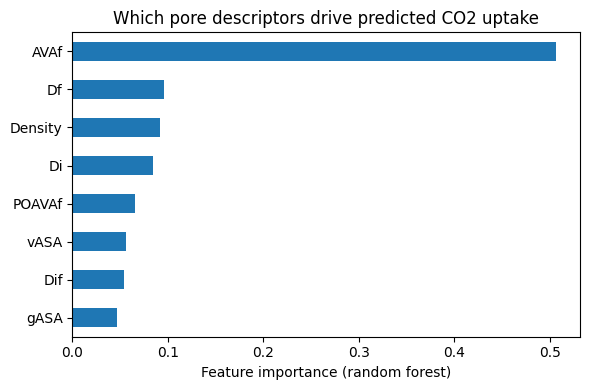

AVAf       0.506396
Df         0.095907
Density    0.091212
Di         0.083902
POAVAf     0.065238
vASA       0.056073
Dif        0.054438
gASA       0.046835
dtype: float64


In [8]:
model.fit(X, y)

importances = pd.Series(model.feature_importances_, index=features).sort_values()
importances.plot(kind='barh', figsize=(6,4))
plt.xlabel('Feature importance (random forest)')
plt.title('Which pore descriptors drive predicted CO2 uptake')
plt.tight_layout()
plt.show()
print(importances.sort_values(ascending=False))

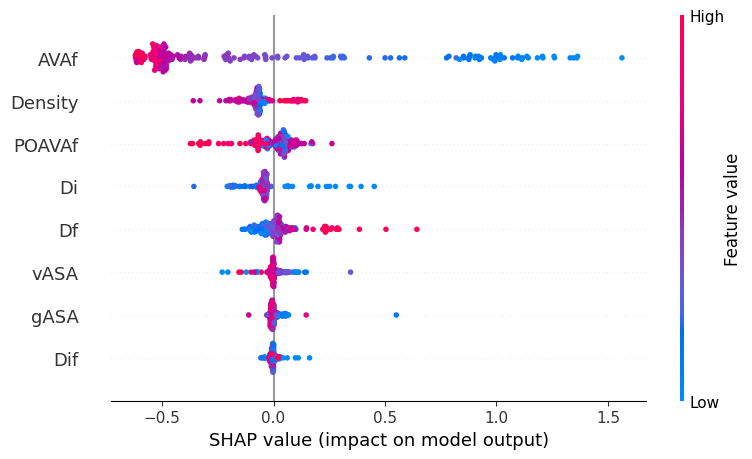

In [9]:
import shap

# Small, shallow model used only for explanation
model_shap = RandomForestRegressor(n_estimators=50, max_depth=8,
                                   min_samples_leaf=10, n_jobs=-1, random_state=42)
model_shap.fit(X, y)

X_explain = X.sample(200, random_state=42)
explainer = shap.TreeExplainer(model_shap)
shap_values = explainer.shap_values(X_explain, check_additivity=False)

shap.summary_plot(shap_values, X_explain)

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


Batch 1/10 done, 29 s elapsed
Batch 2/10 done, 60 s elapsed
Batch 3/10 done, 90 s elapsed
Batch 4/10 done, 119 s elapsed
Batch 5/10 done, 148 s elapsed
Batch 6/10 done, 178 s elapsed
Batch 7/10 done, 207 s elapsed
Batch 8/10 done, 236 s elapsed
Batch 9/10 done, 265 s elapsed
Batch 10/10 done, 294 s elapsed


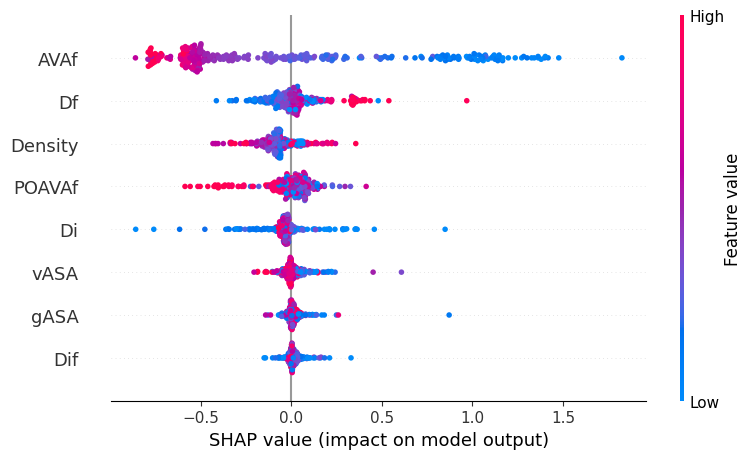

In [10]:
import numpy as np
import time

X_explain = X.sample(300, random_state=42)
explainer_full = shap.TreeExplainer(model)   # the full 200-tree model

batches = np.array_split(X_explain, 10)
shap_full = []
start = time.time()
for i, batch in enumerate(batches, 1):
    shap_full.append(explainer_full.shap_values(batch, check_additivity=False))
    print(f"Batch {i}/10 done, {time.time()-start:.0f} s elapsed")

shap_full = np.vstack(shap_full)
shap.summary_plot(shap_full, X_explain)